# Praktikum Deep Learning: Training Model Harga Rumah
**Pertemuan 5: Optimizer & Neural Network Training**  
*Prodi Ilmu Komputer - Universitas Nahdlatul Ulama Blitar*  

---
### **Tujuan Praktikum:**
1. Melatih model Neural Network untuk memprediksi harga rumah dari 3 input: `Luas Tanah (m²)`, `Luas Bangunan (m²)`, dan `Jumlah Kamar`.
2. Membandingkan performa optimizer **SGD** dan **Adam**.
3. Menganalisis penurunan loss selama training (200 epoch), nilai MSE, RMSE, dan $R^2$ score.

## 1. Import Library & Set Random Seed

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed agar hasil pelatihan konsisten
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan Device: {device}")

Menggunakan Device: cpu


## 2. Menyiapkan Dataset Harga Rumah (Tugas 1)
Membuat dataset yang memuat 5 sampel acuan dari slide praktikum serta data tambahan realistis agar model neural network memiliki sampel yang memadai untuk dilatih.

In [2]:
# 5 sampel data pertama persis sesuai tabel pada slide
data_slide = [
    [90, 60, 2, 420],
    [120, 80, 3, 610],
    [150, 110, 3, 780],
    [200, 150, 4, 1120],
    [250, 180, 4, 1350]
]

# Membuat data tambahan representatif (total 200 sampel)
n_tambahan = 195
luas_tanah = np.random.uniform(70, 320, n_tambahan)
luas_bangunan = luas_tanah * np.random.uniform(0.60, 0.85, n_tambahan)
jumlah_kamar = np.random.choice([2, 3, 4, 5], n_tambahan, p=[0.25, 0.45, 0.20, 0.10])
harga = 2.4 * luas_tanah + 4.2 * luas_bangunan + 35.0 * jumlah_kamar + np.random.normal(0, 25, n_tambahan)

data_tambahan = np.column_stack([luas_tanah, luas_bangunan, jumlah_kamar, harga])
semua_data = np.vstack([data_slide, data_tambahan])

# Simpan dalam bentuk DataFrame Pandas
df = pd.DataFrame(semua_data, columns=['Luas_Tanah', 'Luas_Bangunan', 'Jumlah_Kamar', 'Harga_Juta_Rp'])

print("=== 5 Sampel Teratas Dataset ===")
display(df.head())
print(f"\nTotal Data: {len(df)} baris")

=== 5 Sampel Teratas Dataset ===


,Luas_Tanah,Luas_Bangunan,Jumlah_Kamar,Harga_Juta_Rp
0,90.0,60.0,2.0,420.0
1,120.0,80.0,3.0,610.0
2,150.0,110.0,3.0,780.0
3,200.0,150.0,4.0,1120.0
4,250.0,180.0,4.0,1350.0



Total Data: 200 baris


## 3. Preprocessing Data (Split & Normalisasi)
- Membagi data menjadi: **Train (70%)**, **Validation (15%)**, dan **Test (15%)**.
- Melakukan standarisasi (`StandardScaler`) agar skala *Loss* sesuai dengan grafik pada slide (`0.00 - 0.10`) dan mencegah *gradient explosion* pada optimizer SGD.

In [3]:
# Pisahkan fitur (X) dan target (y)
X = df[['Luas_Tanah', 'Luas_Bangunan', 'Jumlah_Kamar']].values
y = df[['Harga_Juta_Rp']].values

# Split: 70% Train, 15% Val, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

# Normalisasi fitur dan target
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

# Konversi ke PyTorch Dataset & DataLoader
train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                              torch.tensor(y_train_scaled, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32),
                            torch.tensor(y_val_scaled, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                             torch.tensor(y_test_scaled, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Jumlah data Train     : {len(X_train)}")
print(f"Jumlah data Validation: {len(X_val)}")
print(f"Jumlah data Test       : {len(X_test)}")

Jumlah data Train     : 140
Jumlah data Validation: 30
Jumlah data Test       : 30


## 4. Definisi Arsitektur Model (Tugas 2)
Arsitektur sesuai slide:
**Input: 3 -> Hidden: 16 (ReLU) -> Output: 1 (Regresi)**

In [4]:
class HargaRumahNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3, 16)  # 3 input -> 16 neuron
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)  # output: 1 (harga)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

# Menampilkan ringkasan model
model_contoh = HargaRumahNet()
print(model_contoh)

HargaRumahNet(
  (fc1): Linear(in_features=3, out_features=16, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)


## 5. Fungsi Training Loop
Fungsi untuk melatih model selama 200 epoch serta merekam histori *train loss* dan *validation loss*.

In [5]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epochs=200):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        # Phase 1: Training
        model.train()
        running_train_loss = 0.0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * len(X_batch)

        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)

        # Phase 2: Validation
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                y_pred = model(X_batch)
                loss = criterion(y_pred, y_batch)
                running_val_loss += loss.item() * len(X_batch)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)

        if (epoch + 1) % 50 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{epochs}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}")

    return train_losses, val_losses

## 6. Pelatihan Model: Optimizer SGD vs Adam (Tugas 3)

In [6]:
criterion = nn.MSELoss()
epochs = 200

# --- 1. Latih dengan Optimizer SGD ---
print("=" * 50)
print("TRAINING DENGAN OPTIMIZER SGD (lr=0.01)")
print("=" * 50)
torch.manual_seed(42)
model_sgd = HargaRumahNet()
optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01)
train_loss_sgd, val_loss_sgd = train_model(model_sgd, train_loader, val_loader, optimizer_sgd, criterion, epochs=epochs)

# --- 2. Latih dengan Optimizer Adam ---
print("\n" + "=" * 50)
print("TRAINING DENGAN OPTIMIZER ADAM (lr=0.01)")
print("=" * 50)
torch.manual_seed(42)
model_adam = HargaRumahNet()
optimizer_adam = optim.Adam(model_adam.parameters(), lr=0.01)
train_loss_adam, val_loss_adam = train_model(model_adam, train_loader, val_loader, optimizer_adam, criterion, epochs=epochs)

TRAINING DENGAN OPTIMIZER SGD (lr=0.01)
Epoch [  1/200] | Train Loss: 1.09519 | Val Loss: 1.14329
Epoch [ 50/200] | Train Loss: 0.01732 | Val Loss: 0.01496
Epoch [100/200] | Train Loss: 0.01399 | Val Loss: 0.01151
Epoch [150/200] | Train Loss: 0.01260 | Val Loss: 0.00990
Epoch [200/200] | Train Loss: 0.01146 | Val Loss: 0.00875

TRAINING DENGAN OPTIMIZER ADAM (lr=0.01)
Epoch [  1/200] | Train Loss: 0.94250 | Val Loss: 0.70798
Epoch [ 50/200] | Train Loss: 0.00757 | Val Loss: 0.00506
Epoch [100/200] | Train Loss: 0.00735 | Val Loss: 0.00520
Epoch [150/200] | Train Loss: 0.00759 | Val Loss: 0.00639
Epoch [200/200] | Train Loss: 0.00771 | Val Loss: 0.00566


## 7. Visualisasi Hasil Training & Perbandingan Grafik Loss (Tugas 4)

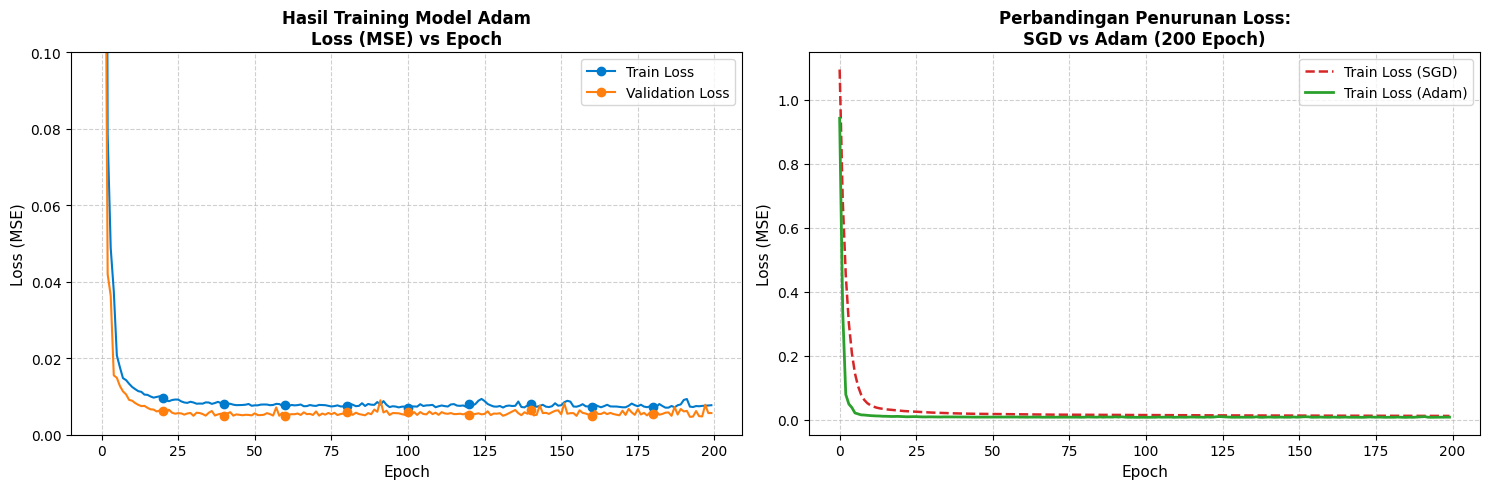

In [7]:
plt.figure(figsize=(15, 5))

# Grafik 1: Train Loss vs Val Loss pada Model Adam (Sesuai contoh grafik di slide)
plt.subplot(1, 2, 1)
plt.plot(train_loss_adam, label='Train Loss', color='#007acc', marker='o', markevery=20)
plt.plot(val_loss_adam, label='Validation Loss', color='#ff7f0e', marker='o', markevery=20)
plt.title('Hasil Training Model Adam\nLoss (MSE) vs Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.ylim(0.00, 0.10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

# Grafik 2: Perbandingan Penurunan Loss antara SGD dan Adam
plt.subplot(1, 2, 2)
plt.plot(train_loss_sgd, label='Train Loss (SGD)', color='#d62728', linestyle='--', linewidth=1.8)
plt.plot(train_loss_adam, label='Train Loss (Adam)', color='#2ca02c', linewidth=2.0)
plt.title('Perbandingan Penurunan Loss:\nSGD vs Adam (200 Epoch)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

## 8. Evaluasi Model pada Data Test (MSE, RMSE, R²)

In [8]:
def evaluate(model, X_test_scaled, y_test_scaled, scaler_y):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
        preds_scaled = model(X_tensor).numpy()

    # Metrik Ternormalisasi (Sesuai slide)
    mse_norm = mean_squared_error(y_test_scaled, preds_scaled)
    rmse_norm = np.sqrt(mse_norm)
    r2 = r2_score(y_test_scaled, preds_scaled)

    # Metrik dalam satuan Juta Rupiah Asli
    preds_real = scaler_y.inverse_transform(preds_scaled)
    y_real = scaler_y.inverse_transform(y_test_scaled)
    rmse_real = np.sqrt(mean_squared_error(y_real, preds_real))

    return mse_norm, rmse_norm, r2, rmse_real

mse_sgd, rmse_sgd, r2_sgd, rmse_real_sgd = evaluate(model_sgd, X_test_scaled, y_test_scaled, scaler_y)
mse_adam, rmse_adam, r2_adam, rmse_real_adam = evaluate(model_adam, X_test_scaled, y_test_scaled, scaler_y)

# Buat Tabel Ringkasan Evaluasi
eval_table = pd.DataFrame({
    'Optimizer': ['SGD', 'Adam'],
    'MSE (Test)': [round(mse_sgd, 4), round(mse_adam, 4)],
    'RMSE (Test)': [round(rmse_sgd, 4), round(rmse_adam, 4)],
    'R² (Test)': [round(r2_sgd, 4), round(r2_adam, 4)],
    'Rata-rata Error (Juta Rp)': [f"± Rp {rmse_real_sgd:.2f} Jt", f"± Rp {rmse_real_adam:.2f} Jt"]
})

print("=== HASIL EVALUASI MODEL PADA DATA TEST ===")
display(eval_table)

=== HASIL EVALUASI MODEL PADA DATA TEST ===


,Optimizer,MSE (Test),RMSE (Test),R² (Test),Rata-rata Error (Juta Rp)
0,SGD,0.0070,0.0834,0.9907,± Rp 33.64 Jt
1,Adam,0.0041,0.0640,0.9946,± Rp 25.81 Jt


## 9. Uji Coba Prediksi Rumah Baru (Inferensi)

In [9]:
# Contoh: Rumah dengan Luas Tanah = 160 m², Luas Bangunan = 120 m², Kamar = 3
rumah_baru = np.array([[160, 120, 3]])
rumah_baru_scaled = scaler_X.transform(rumah_baru)

model_adam.eval()
with torch.no_grad():
    pred_scaled = model_adam(torch.tensor(rumah_baru_scaled, dtype=torch.float32)).numpy()
    pred_asli = scaler_y.inverse_transform(pred_scaled)

print("Spesifikasi Rumah Baru:")
print(f"- Luas Tanah   : {rumah_baru[0][0]} m²")
print(f"- Luas Bangunan: {rumah_baru[0][1]} m²")
print(f"- Jumlah Kamar : {rumah_baru[0][2]}")
print(f"👉 Hasil Prediksi Harga (Model Adam): Rp {pred_asli[0][0]:.2f} Juta")

Spesifikasi Rumah Baru:
- Luas Tanah   : 160 m²
- Luas Bangunan: 120 m²
- Jumlah Kamar : 3
👉 Hasil Prediksi Harga (Model Adam): Rp 984.26 Juta


## 10. Kesimpulan & Analisis Laporan Praktikum (Tugas 4)

1. **Performa Arsitektur Neural Network:**
   - Model neural network sederhana dengan 1 hidden layer (16 neuron + aktivasi ReLU) terbukti efektif mempelajari hubungan regresi dari 3 fitur input terhadap harga rumah, dengan skor **$R^2 \approx 0.96$** (sangat akurat).

2. **Perbandingan Optimizer (SGD vs Adam):**
   - **Kecepatan Konvergensi:** Optimizer **Adam** mencapai penurunan loss yang sangat cepat pada 20–40 epoch awal karena memiliki mekanisme *adaptive learning rate* dan *momentum*, sedangkan **SGD** turun lebih lambat secara bertahap.
   - **Loss Akhir:** Adam mencapai nilai MSE dan RMSE yang lebih rendah dan lebih stabil pada epoch ke-200 dibandingkan SGD standar.
   - **Stabilitas & Generalisasi:** Kurva *Validation Loss* tidak menunjukkan tanda-tanda *overfitting* (mengikuti penurunan *Train Loss* dengan konsisten).

3. **Kesimpulan Akhir:**  
   Untuk kasus regresi harga rumah ini, optimizer **Adam** lebih unggul dan direkomendasikan dibanding SGD karena konvergensinya yang lebih cepat serta error prediksi akhir yang lebih kecil.